# 05 · LSTM e o pipeline de verificação de notícias

**O que este notebook faz:**
1. Treina uma rede neural **LSTM** (pedido do professor) no Fake.br e testa no corpus novo de 2026.
2. Compara a LSTM com a Regressão Logística (TF-IDF), **nas mesmas condições**.
3. Mostra o **pipeline completo**: entra uma notícia, ela passa por cada etapa e sai o veredito (fake ou fato).

**Antes de rodar:** suba o arquivo `corpus_atualizado_v2.csv` pelo ícone de pasta. Se quiser mais rápido, use GPU em *Ambiente de execução > Alterar o tipo de ambiente de execução > T4 GPU* (sem GPU também funciona).

## Célula 1 · Baixar o Fake.br

In [ ]:
![ -d Fake.br-Corpus ] || git clone -q https://github.com/roneysco/Fake.br-Corpus.git
!ls Fake.br-Corpus/full_texts

fake  fake-meta-information  true  true-meta-information


## Célula 2 · Carregar os dados
Fake.br (7.200 notícias de 2018) e o corpus novo (100 notícias de outubro de 2026). Todos os textos são cortados em 150 palavras, pra ficarem do mesmo tamanho.

In [ ]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf

tf.keras.utils.set_random_seed(42)

def ler_noticias(pasta, label):
    dados = []
    for nome in sorted(os.listdir(pasta)):
        with open(os.path.join(pasta, nome), "r", encoding="utf-8") as f:
            dados.append({"texto": f.read(), "label": label})
    return dados

df = pd.DataFrame(ler_noticias("Fake.br-Corpus/full_texts/true", 0) + ler_noticias("Fake.br-Corpus/full_texts/fake", 1))
df["texto_150"] = df["texto"].apply(lambda t: " ".join(t.split()[:150]))

# acha o corpus novo onde quer que ele tenha sido subido
for caminho in ["corpus_atualizado_v2.csv", "/corpus_atualizado_v2.csv", "/content/corpus_atualizado_v2.csv"]:
    if os.path.exists(caminho):
        novo = pd.read_csv(caminho)
        break
else:
    raise FileNotFoundError("Suba o arquivo corpus_atualizado_v2.csv pelo ícone de pasta")

print("Fake.br:", df.shape)
print("Corpus novo:", novo.shape, novo["label"].value_counts().to_dict())

Fake.br: (7200, 3)
Corpus novo: (100, 7) {0: 60, 1: 40}


## Célula 3 · Separar treino e teste
80% pra treinar e 20% pra testar, a mesma divisão (`random_state=42`) pra todos os modelos.

In [ ]:
from sklearn.model_selection import train_test_split

X_treino, X_teste, y_treino, y_teste = train_test_split(
    df["texto_150"], df["label"], test_size=0.2, random_state=42
)
print(len(X_treino), "pra treinar |", len(X_teste), "pra testar")

5760 pra treinar | 1440 pra testar


## Célula 4 · Referência: Regressão Logística com TF-IDF
O melhor modelo clássico no corpus novo, treinado aqui nas mesmas condições da LSTM, pra comparação ser justa.

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, recall_score, classification_report

tfidf = TfidfVectorizer(max_features=5000)
X_treino_tfidf = tfidf.fit_transform(X_treino)

reg_log = LogisticRegression(max_iter=1000)
reg_log.fit(X_treino_tfidf, y_treino)

def avaliar(nome, prev_fakebr, prev_novo):
    return {
        "modelo": nome,
        "acuracia_fakebr": accuracy_score(y_teste, prev_fakebr),
        "acuracia_novo": accuracy_score(novo["label"], prev_novo),
        "acerto_falsas_novo": recall_score(novo["label"], prev_novo, pos_label=1),
        "acerto_verdadeiras_novo": recall_score(novo["label"], prev_novo, pos_label=0),
    }

resultados = [avaliar(
    "Regressão Logística (TF-IDF)",
    reg_log.predict(tfidf.transform(X_teste)),
    reg_log.predict(tfidf.transform(novo["texto_truncado"])),
)]
pd.DataFrame(resultados).round(4)

,modelo,acuracia_fakebr,acuracia_novo,acerto_falsas_novo,acerto_verdadeiras_novo
0,Regressão Logística (TF-IDF),0.9271,0.87,0.775,0.9333


## Célula 5 · Transformar o texto em sequência de números
A LSTM não usa TF-IDF. Ela recebe a notícia como uma **sequência**: cada palavra vira o número dela no vocabulário, **na ordem em que aparece**. Assim a rede consegue levar em conta a ordem das palavras, coisa que o TF-IDF ignora.

In [ ]:
VOCAB = 20000    # as 20 mil palavras mais frequentes
TAMANHO = 150    # 150 posições por notícia

vetorizador = tf.keras.layers.TextVectorization(max_tokens=VOCAB, output_sequence_length=TAMANHO)
vetorizador.adapt(X_treino.values)   # aprende o vocabulário só com o treino

def para_sequencia(textos):
    return vetorizador(tf.constant(list(textos)))

seq_treino = para_sequencia(X_treino)
seq_teste = para_sequencia(X_teste)
seq_novo = para_sequencia(novo["texto_truncado"])

# exemplo pra mostrar: as 8 primeiras palavras de uma notícia e os números delas
exemplo = X_treino.iloc[0]
vocab = vetorizador.get_vocabulary()
numeros = para_sequencia([exemplo])[0][:8].numpy()
for n in numeros:
    print(f"{vocab[n]:>15}  ->  {n}")

           maia  ->  520
           pede  ->  373
            que  ->  5
            stf  ->  83
         decida  ->  6648
          sobre  ->  40
      andamento  ->  1967
             de  ->  2


## Célula 6 · Montar e treinar a LSTM
- **Embedding:** transforma o número de cada palavra num vetor de 64 valores que representa o significado dela (aprendido no treino).
- **LSTM:** lê a notícia palavra por palavra, em ordem, guardando uma "memória" do que já leu.
- **Dropout:** desliga 30% dos neurônios aleatoriamente no treino, pra rede não decorar.
- **Dense com sigmoide:** dá a saída final, a probabilidade de a notícia ser fake (de 0 a 1).

O treino para sozinho quando o erro na validação para de melhorar (*early stopping*).

In [ ]:
def criar_modelo(bidirecional=False):
    camada = tf.keras.layers.LSTM(64)
    if bidirecional:
        camada = tf.keras.layers.Bidirectional(camada)
    modelo = tf.keras.Sequential([
        tf.keras.Input(shape=(TAMANHO,)),
        tf.keras.layers.Embedding(VOCAB, 64, mask_zero=True),
        camada,
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])
    modelo.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return modelo

parar_cedo = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

lstm = criar_modelo()
lstm.summary()
historico = lstm.fit(seq_treino, y_treino.values, validation_split=0.1,
                     epochs=10, batch_size=64, callbacks=[parar_cedo], verbose=2)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 150, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
81/81 - 26s - 316ms/step - accuracy: 0.6678 - loss: 0.5851 - val_accuracy: 0.8090 - val_loss: 0.4353
Epoch 2/10
81/81 - 13s - 158ms/step - accuracy: 0.9169 - loss: 0.2475 - val_accuracy: 0.8993 - val_loss: 0.2809
Epoch 3/10
81/81 - 9s - 107ms/step - accuracy: 0.9757 - loss: 0.0949 - val_accuracy: 0.9167 - val_loss: 0.3730
Epoch 4/10
81/81 - 11s - 132ms/step - accuracy: 0.9877 - loss: 0.0620 - val_accuracy: 0.8924 - val_loss: 0.4410
Epoch 5/10
81/81 - 11s - 139ms/step - accuracy: 0.9861 - loss: 0.0557 - val_accuracy: 0.9097 - val_loss: 0.2586
Epoch 6/10
81/81 - 11s - 139ms/step - accuracy: 0.9896 - loss: 0.0416 - val_accuracy: 0.8819 - val_loss: 0.5395
Epoch 7/10
81/81 - 10s - 125ms/step - accuracy: 0.9880 - loss: 0.0490 - val_accuracy: 0.8681 - val_loss: 0.3912
Epoch 8/10
81/81 - 9s - 107ms/step - accuracy: 0.9840 - loss: 0.0520 - val_accuracy: 0.8542 - val_loss: 0.3222


## Célula 7 · Avaliar a LSTM
Testa nas 1.440 notícias do Fake.br que a rede nunca viu e nas 100 notícias de 2026.

In [ ]:
def prever(modelo, seq):
    return (modelo.predict(seq, verbose=0).ravel() >= 0.5).astype(int)

prev_lstm_teste = prever(lstm, seq_teste)
print(classification_report(y_teste, prev_lstm_teste, digits=4))

resultados.append(avaliar("LSTM", prev_lstm_teste, prever(lstm, seq_novo)))
pd.DataFrame(resultados).round(4)

              precision    recall  f1-score   support

           0     0.9376    0.8997    0.9183       718
           1     0.9041    0.9404    0.9219       722

    accuracy                         0.9201      1440
   macro avg     0.9209    0.9201    0.9201      1440
weighted avg     0.9208    0.9201    0.9201      1440



,modelo,acuracia_fakebr,acuracia_novo,acerto_falsas_novo,acerto_verdadeiras_novo
0,Regressão Logística (TF-IDF),0.9271,0.87,0.775,0.9333
1,LSTM,0.9201,0.76,0.575,0.8833


## Célula 8 · Variação: LSTM bidirecional
A mesma rede, mas lendo a notícia nos dois sentidos (do começo pro fim e do fim pro começo). Costuma entender melhor o contexto, mas demora mais pra treinar.

In [ ]:
bilstm = criar_modelo(bidirecional=True)
bilstm.fit(seq_treino, y_treino.values, validation_split=0.1,
           epochs=10, batch_size=64, callbacks=[parar_cedo], verbose=2)

resultados.append(avaliar("LSTM bidirecional", prever(bilstm, seq_teste), prever(bilstm, seq_novo)))
tabela = pd.DataFrame(resultados).round(4)
tabela.to_csv("resultado_lstm.csv", index=False)
tabela

Epoch 1/10
81/81 - 23s - 280ms/step - accuracy: 0.7400 - loss: 0.5179 - val_accuracy: 0.8785 - val_loss: 0.2942
Epoch 2/10
81/81 - 17s - 214ms/step - accuracy: 0.8837 - loss: 0.2573 - val_accuracy: 0.8976 - val_loss: 0.2848
Epoch 3/10
81/81 - 20s - 251ms/step - accuracy: 0.9572 - loss: 0.1271 - val_accuracy: 0.8906 - val_loss: 0.3165


,modelo,acuracia_fakebr,acuracia_novo,acerto_falsas_novo,acerto_verdadeiras_novo
0,Regressão Logística (TF-IDF),0.9271,0.87,0.775,0.9333
1,LSTM,0.9201,0.76,0.575,0.8833
2,LSTM bidirecional,0.8764,0.79,0.500,0.9833


## Célula 9 · Gráfico comparativo

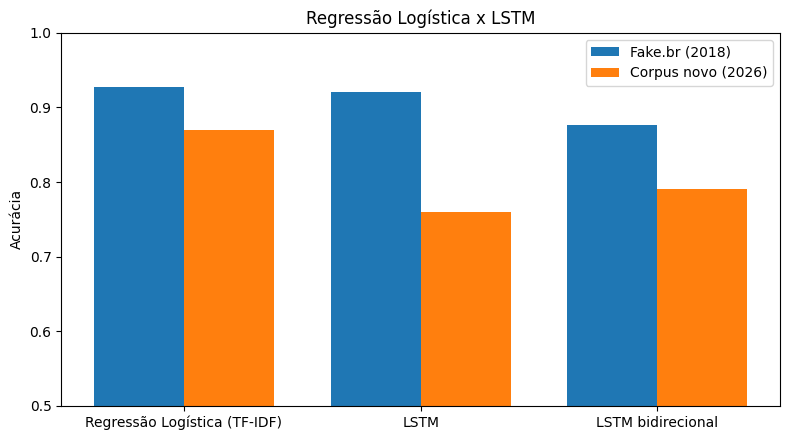

In [ ]:
import matplotlib.pyplot as plt

x = np.arange(len(tabela))
w = 0.38
plt.figure(figsize=(8, 4.5))
plt.bar(x - w / 2, tabela["acuracia_fakebr"], w, label="Fake.br (2018)")
plt.bar(x + w / 2, tabela["acuracia_novo"], w, label="Corpus novo (2026)")
plt.xticks(x, tabela["modelo"])
plt.ylim(0.5, 1.0)
plt.ylabel("Acurácia")
plt.title("Regressão Logística x LSTM")
plt.legend()
plt.tight_layout()
plt.show()

## Célula 10 · O pipeline: verificar uma notícia
Esta função mostra o que acontece com uma notícia, etapa por etapa, até o veredito. O modelo principal é a Regressão Logística (o melhor no corpus novo), e a LSTM aparece como segunda opinião.

In [ ]:
def verificar_noticia(texto):
    print("=" * 70)
    print("1) ENTRADA")
    print("   ", texto[:200].replace("\n", " "), "...")

    palavras = texto.split()
    texto_150 = " ".join(palavras[:150])
    print("\n2) PRÉ-PROCESSAMENTO")
    print(f"    A notícia tinha {len(palavras)} palavras, ficou com {min(len(palavras), 150)}.")
    print("    Tudo em minúsculas, sem pontuação.")

    vetor = tfidf.transform([texto_150])
    print("\n3) REPRESENTAÇÃO")
    print(f"    TF-IDF: vetor de {vetor.shape[1]} posições, {vetor.nnz} preenchidas (palavras conhecidas que apareceram).")
    seq = para_sequencia([texto_150])
    print(f"    LSTM: sequência de {TAMANHO} números, começando por {seq[0][:6].numpy().tolist()}...")

    prob_lr = reg_log.predict_proba(vetor)[0, 1]
    prob_lstm = float(lstm.predict(seq, verbose=0)[0, 0])
    print("\n4) MODELOS (probabilidade de ser fake)")
    print(f"    Regressão Logística: {prob_lr:.0%}")
    print(f"    LSTM:                {prob_lstm:.0%}")

    contrib = vetor.toarray()[0] * reg_log.coef_[0]
    nomes = tfidf.get_feature_names_out()
    pro_fake = [nomes[i] for i in np.argsort(contrib)[::-1][:5] if contrib[i] > 0]
    pro_fato = [nomes[i] for i in np.argsort(contrib)[:5] if contrib[i] < 0]
    print("\n5) POR QUÊ (palavras que mais pesaram na Regressão Logística)")
    print("    Puxaram pra FAKE:", ", ".join(pro_fake) or "nenhuma")
    print("    Puxaram pra FATO:", ", ".join(pro_fato) or "nenhuma")

    veredito = "FAKE" if prob_lr >= 0.5 else "FATO"
    print("\n6) VEREDITO:", veredito, f"(confiança de {max(prob_lr, 1 - prob_lr):.0%})")
    print("=" * 70)

## Célula 11 · Testando o pipeline
Uma fake news e uma notícia verdadeira do corpus novo. Pra testar outra notícia, é só colar o texto entre as aspas triplas da última linha.

In [ ]:
fake_exemplo = novo[novo["label"] == 1]["texto_truncado"].iloc[0]
fato_exemplo = novo[novo["label"] == 0]["texto_truncado"].iloc[0]

verificar_noticia(fake_exemplo)
verificar_noticia(fato_exemplo)

# verificar_noticia("""cole aqui o texto de uma notícia""")

1) ENTRADA
    A Coca-Cola fechou quatro fábricas no Brasil e demitiu cerca de 1.400 funcionários por causa do governo Lula e do PT. Publicações nas redes sociais passaram a compartilhar notícias sobre o fechamento  ...

2) PRÉ-PROCESSAMENTO
    A notícia tinha 150 palavras, ficou com 150.
    Tudo em minúsculas, sem pontuação.

3) REPRESENTAÇÃO
    TF-IDF: vetor de 5000 posições, 64 preenchidas (palavras conhecidas que apareceram).
    LSTM: sequência de 150 números, começando por [4, 10957, 2226, 325, 12316, 11]...

4) MODELOS (probabilidade de ser fake)
    Regressão Logística: 72%
    LSTM:                99%

5) POR QUÊ (palavras que mais pesaram na Regressão Logística)
    Puxaram pra FAKE: lula, pt, brasil, está, teria
    Puxaram pra FATO: de, no, do, segundo, quatro

6) VEREDITO: FAKE (confiança de 72%)
1) ENTRADA
    O Tribunal Superior Eleitoral fixou nesta terça-feira (13) limites para que as campanhas do presidente Luiz Inácio Lula da Silva (PT) e Flávio Bolsonaro (PL) ao 

In [ ]:
minha_noticia = """
Lula já estave envolvido em escândalos de corrupção.
"""

verificar_noticia(minha_noticia)

1) ENTRADA
     Lula já estave envolvido em escândalos de corrupção.  ...

2) PRÉ-PROCESSAMENTO
    A notícia tinha 8 palavras, ficou com 8.
    Tudo em minúsculas, sem pontuação.

3) REPRESENTAÇÃO
    TF-IDF: vetor de 5000 posições, 7 preenchidas (palavras conhecidas que apareceram).
    LSTM: sequência de 150 números, começando por [23, 45, 1, 4263, 9, 3303]...

4) MODELOS (probabilidade de ser fake)
    Regressão Logística: 93%
    LSTM:                62%

5) POR QUÊ (palavras que mais pesaram na Regressão Logística)
    Puxaram pra FAKE: lula, já, corrupção, envolvido, escândalos
    Puxaram pra FATO: em, de

6) VEREDITO: FAKE (confiança de 93%)
